# 01 Data: the Criteo test and the Iowa panel

Two datasets, two jobs:

- **Criteo Uplift v2.1**: a real randomised ad test on 13,979,592 users. Findings 1 to 7 and 9.
- **Iowa Liquor Sales**: real weekly sales for Iowa's counties, used with *simulated* campaigns to grade geo-test methods (finding 8).

Both are prepared by scripts in `python/scripts/` (`criteo_to_parquet.py`, `iowa_panel.py`); this notebook looks at what came out.

In [1]:
from pathlib import Path
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from incrementality.style import PAL, SOURCE, SOURCE_IOWA, apply, finish

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CRITEO = (ROOT / "data" / "processed" / "criteo_uplift.parquet").as_posix()
results = lambda name: json.loads((ROOT / "results" / f"{name}.json").read_text(encoding="utf-8"))
show = lambda name: display(Image(filename=str(ROOT / "figures" / name), width=900))
pd.set_option("display.float_format", "{:,.4f}".format)
apply()

## Criteo: who was treated, who saw an ad, who converted

85% of users were randomly allowed to see the retailer's ads (treatment); 15% had ads blocked (control). Being allowed to see ads doesn't mean you will: `exposure` records who actually saw one.

In [2]:
cells = duckdb.sql(f"""
    SELECT treatment, exposure, count(*) AS users,
           avg(visit) AS visit_rate, avg(conversion) AS conversion_rate
    FROM '{CRITEO}' GROUP BY ALL ORDER BY ALL""").df()
cells["share_of_all_users"] = cells["users"] / cells["users"].sum()
cells

,treatment,exposure,users,visit_rate,conversion_rate,share_of_all_users
0,0,0,2096937,0.0382,0.0019,0.1500
1,1,0,11454443,0.0349,0.0012,0.8194
2,1,1,428212,0.4145,0.0538,0.0306


Three things to notice:

1. **No control user saw an ad** (there is no `treatment = 0, exposure = 1` row). That makes the effect of seeing an ad measurable (notebook 03).
2. **Only about 3.6% of treated users saw an ad.** The rest were allowed to but never were.
3. **Users who saw an ad convert far more often** than everyone else. Notebook 03 shows how little of that gap the ad itself caused.

In [3]:
duckdb.sql(f"SUMMARIZE SELECT * FROM '{CRITEO}'").df()[
    ["column_name", "min", "max", "avg", "std", "null_percentage"]]

,column_name,min,max,avg,std,null_percentage
0,f0,12.616364906986497,26.74525510669564,19.62029748729208,5.377463821796478,0.0000
1,f1,10.059654474774547,16.34418683323554,10.069976509544523,0.104755730819988,0.0000
2,f2,8.214382844395335,9.051961945804948,8.446582306857527,0.299316099793664,0.0000
3,f3,-8.39838674285089,4.679881620097284,4.178923067851077,1.3366449970832466,0.0000
4,f4,10.280525225748212,21.123507734315055,10.33883729505766,0.34330814892133277,0.0000
5,f5,-9.011891520498516,4.115453421277861,4.028512923153235,0.43109744433859765,0.0000
6,f6,-31.429783775633886,0.29444271125560606,-4.155355515100793,4.577914125554656,0.0000
7,f7,4.833814577796811,11.998400591725755,5.101764646567713,1.2052477300984148,0.0000
8,f8,3.63510661177053,3.971857989350875,3.933580837968864,0.056659584421810856,0.0000
9,f9,13.190055934673358,75.29501735734412,16.02763833006484,7.018974878926266,0.0000


The 12 features (`f0` to `f11`) are anonymised and randomly projected by Criteo, so they can't be interpreted, only used. No column has missing values.

## Iowa: weekly sales per county

Pulled with `sql/iowa_county_week.sql` in BigQuery, then cleaned by `iowa_panel.py`: county names standardised, three counties with many empty weeks left out, and the remaining holiday-week gaps filled from neighbouring weeks.

In [4]:
s = results("iowa_panel")
panel = pd.read_parquet(ROOT / "data" / "processed" / "iowa_log_sales.parquet")  # log of weekly sales
print(f"{s['counties']} counties x {s['weeks']} weeks, {s['first_week']} to {s['last_week']}")
print("Left out for gaps:", ", ".join(f"{c} ({v:.0%} of weeks empty)" for c, v in s["counties_left_out_for_gaps"].items()))
print(f"County-weeks filled: {s['county_weeks_missing_or_zero']} of {s['counties'] * s['weeks']:,}")

96 counties x 537 weeks, 2016-01-11 to 2026-04-20
Left out for gaps: Fremont (31% of weeks empty), Davis (10% of weeks empty), Adams (9% of weeks empty)
County-weeks filled: 439 of 51,552


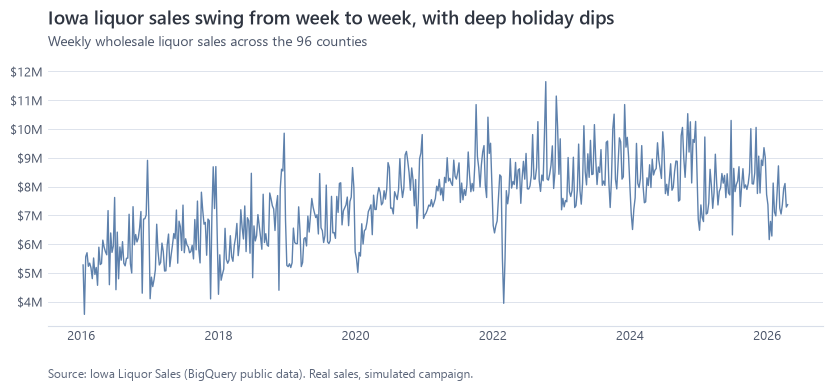

In [5]:
state = np.exp(panel).sum(axis=1) / 1e6
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(state.index, state, color=PAL["primary"], lw=1)
ax.yaxis.set_major_formatter(lambda v, _: f"${v:.0f}M")
finish(fig, ax, "Iowa liquor sales swing from week to week, with deep holiday dips",
       "Weekly wholesale liquor sales across the 96 counties", source=SOURCE_IOWA)
plt.show()

Weekly sales are lumpy because stores order in batches, and holiday weeks (Labor Day, Memorial Day, Thanksgiving) dip sharply. That noise is exactly what makes geo tests hard (notebook 05).